# 06 — Separating the Causes
**Stage:** Evaluation

**TL;DR:** > **Revised in Notebook 07:** two natural experiments (2016 and a rain-adjusted 2024) bracket the failed-monsoon share at **~24–78%**; the data cannot say which cause was larger. The ≤13% free-electricity figure below is a reference estimate only (weak inputs).

**Free electricity or failed monsoon?** For the ~1,860 MW of extra demand in Aug–Oct 2023: the **failed monsoon** explains **~445–664 MW (25–35%)**, a temporary effect that rises on dry days and vanished when rain returned. **Free electricity (Gruha Jyothi)** can explain **at most ~240 MW (≤13%)**, based on official household consumption growth. The rest, **~1,000–1,400 MW (50–75%)**, is an **"other" lasting increase** that neither cause explains: it is still there in 2024–25, equal on Sundays and weekdays, and sits mostly in day/night hours.

## 1. Question
Notebook 05 found that Aug–Oct 2023 demand was **~1,860 MW above** the calendar + heat + trend expectation
(Model A), made of a **temporary rain-related part** and a **persistent step (~1,400 MW)** that is still there in
2024–25. Now:

1. **When** did the persistent step start — sharply on 1 Aug (policy switch-on) or gradually?
2. **How big is the drought effect**, measured *directly from 2023* rather than learned from older years?
3. **In which hours** does each part sit (fingerprints)?
4. Does the step behave like **households, farms, or businesses** (weekday vs Sunday)?
5. Is the step's size consistent with **official household consumption figures** for Gruha Jyothi?

## 2. Expectation *(written before running)*
- If the persistent step is **Gruha Jyothi**, it should switch on around **1 Aug** (the benefit applied from the
  July/August consumption), sit in **household hours**, look **the same on Sundays** (people at home), and its size
  should match official **household** consumption growth.
- The **drought effect** should be visible *within* Aug–Dec 2023: on drier days, demand above Model A should be
  higher. Because the scheme was constant after 1 Aug, this link cannot be the scheme.
- From Notebook 05, I already suspect the step sits mostly in **day/night** hours — which would fit farm demand
  better than households.

## 3. Data used
`counterfactual_hourly.parquet` and `backtest_hourly.parquet` (Notebook 05), rain anomalies (`src/features.py`).
External: Karnataka Economic Survey 2017-18 category shares (via ThePrint), news reports of household consumption
growth in the first year of Gruha Jyothi (Deccan Herald, Varthabharati, Mangalore Today).

**Key idea for Step 4.2:** after 1 Aug 2023 the scheme did not change from day to day, so **day-to-day variation**
in the excess can only come from things that do vary — like rain.

In [1]:
import sys, warnings
from pathlib import Path
sys.path.append(str(Path.cwd().parent))
warnings.filterwarnings("ignore")

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import statsmodels.api as sm
from src import config, plots, features as F

plots.setup()
pd.set_option("display.width", 200)
P = config.DATA_PROCESSED

cf = pd.read_parquet(P / "counterfactual_hourly.parquet")
bt = pd.read_parquet(P / "backtest_hourly.parquet")
df = F.build_hourly_frame(pd.read_parquet(P / "load_hourly.parquet"), pd.read_parquet(P / "weather_daily.parquet"),
                          pd.read_parquet(P / "weather_hourly_blr.parquet"), pd.read_parquet(P / "holidays.parquet"))
anom = df.groupby(df.index.normalize())[["rain_7d_anom", "rain_30d_anom", "rain_60d_anom"]].first()
farm_rain = pd.read_parquet(P / "weather_daily.parquet").farm_rain_mm

d = cf.resample("D").mean().dropna()
d["gap_A_%"] = (d.load_mw / d.pred_A - 1) * 100          # excess over calendar + heat + trend
d["gap_B_%"] = (d.load_mw / d.pred_B - 1) * 100          # excess after rain is also accounted for
d = d.join(anom)
cf["hour"], cf["dow"] = cf.index.hour, cf.index.dayofweek
SCHEME = pd.Timestamp(config.SCHEME_START)

## 4. Analysis
### Step 4.1 — When did the persistent step start?
*Why:* a policy that switches on should produce a **sharp** change at its start date. Use the excess over Model B
(rain already accounted for) and find the single date that best splits it into "before" and "after"
(a simple change-point search: minimise squared error of a two-level model).

Best single change point: 2023-08-14  (before: +4.7%, after: +16.9%)
Next best dates: [datetime.date(2023, 8, 12), datetime.date(2023, 8, 13), datetime.date(2023, 8, 11), datetime.date(2023, 8, 16)]
If forced at 1 Aug: before +3.5%, after +14.6%  (fit is 52% worse than best)


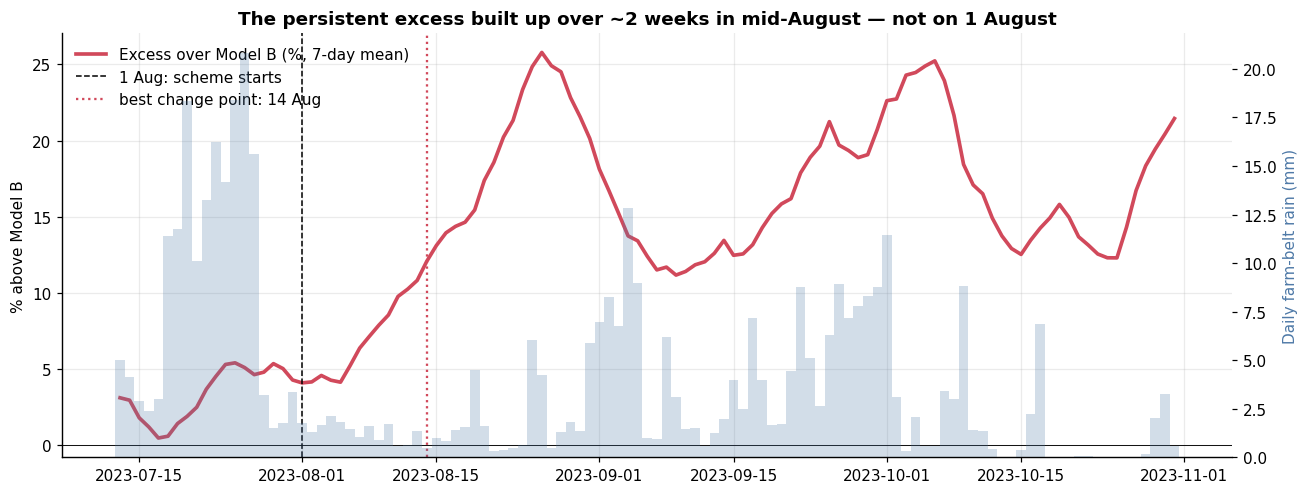

In [2]:
w = d.loc["2023-07-13":"2023-09-30", "gap_B_%"]
scores = []
for c in w.index[5:-5]:
    a, b = w[w.index < c], w[w.index >= c]
    scores.append((((a - a.mean()) ** 2).sum() + ((b - b.mean()) ** 2).sum(), c, a.mean(), b.mean()))
scores.sort()
sse, cp, before, after = scores[0]
print(f"Best single change point: {cp.date()}  (before: {before:+.1f}%, after: {after:+.1f}%)")
print("Next best dates:", [s[1].date() for s in scores[1:5]])
sse_aug1 = [s for s in scores if s[1] == SCHEME][0]
print(f"If forced at 1 Aug: before {sse_aug1[2]:+.1f}%, after {sse_aug1[3]:+.1f}%  (fit is {(sse_aug1[0] / sse - 1) * 100:.0f}% worse than best)")

fig, ax1 = plt.subplots(figsize=(12, 4.6))
s7 = d.loc["2023-07-13":"2023-10-31", "gap_B_%"].rolling(7, center=True, min_periods=3).mean()
ax1.plot(s7.index, s7.values, color=plots.COLORS["highlight"], lw=2.4, label="Excess over Model B (%, 7-day mean)")
ax1.axvline(SCHEME, color="black", ls="--", lw=1, label="1 Aug: scheme starts")
ax1.axvline(cp, color=plots.COLORS["highlight"], ls=":", lw=1.5, label=f"best change point: {cp:%d %b}")
ax1.axhline(0, color="black", lw=0.6)
ax1.set_ylabel("% above Model B")
ax2 = ax1.twinx(); ax2.grid(False)
rr = farm_rain["2023-07-13":"2023-10-31"]
ax2.bar(rr.index, rr.values, color=plots.COLORS["hydro"], alpha=0.25, width=1)
ax2.set_ylabel("Daily farm-belt rain (mm)", color=plots.COLORS["hydro"])
ax1.set_title("The persistent excess built up over ~2 weeks in mid-August — not on 1 August")
ax1.legend(loc="upper left")
plt.tight_layout(); plots.save(fig, "06_step_timing"); plt.show()

### Step 4.2 — The drought effect, measured inside 2023
*Why:* within Aug–Dec 2023 the scheme was constant, so if the excess over Model A rises on drier days, that link
is the drought. Regression (one per year): `excess_A% = intercept + slope × rain_30d_anomaly`.
- **slope** = how much demand rises per 100 mm of rain shortfall,
- **intercept** = the excess at *normal* rain → the persistent part,
- standard errors are Newey–West (HAC) because daily values are autocorrelated.

The same regression on the **out-of-sample backtest years** (2019, 2021, 2022) checks whether the drought
sensitivity is a stable, long-standing behaviour.

In [3]:
def rain_regression(frame, y="gap_A_%", x="rain_30d_anom"):
    X = sm.add_constant(frame[x] / 100)
    r = sm.OLS(frame[y], X).fit(cov_type="HAC", cov_kwds={"maxlags": 14})
    return {"n days": len(frame), "intercept %": r.params.iloc[0], "intercept se": r.bse.iloc[0],
            "slope % per 100mm": r.params.iloc[1], "slope se": r.bse.iloc[1], "R²": r.rsquared}

b = bt[bt.model == "A"]
bd = b.groupby(b.index.normalize())[["actual", "pred"]].mean()
bd["gap_A_%"] = (bd.actual / bd.pred - 1) * 100
bd = bd.join(anom)

rows = {"Backtest 2019/21/22 (no scheme)": rain_regression(bd[bd.index.month.isin([8, 9, 10, 11, 12])])}
for yr in [2023, 2024, 2025]:
    rows[f"Aug–Dec {yr}"] = rain_regression(d.loc[f"{yr}-08-01":f"{yr}-12-31"])
reg = pd.DataFrame(rows).T.round(2)
reg

,n days,intercept %,intercept se,slope % per 100mm,slope se,R²
Backtest 2019/21/22 (no scheme),459.0,3.91,1.99,-16.74,2.40,0.42
Aug–Dec 2023,153.0,12.88,1.99,-12.95,2.57,0.25
Aug–Dec 2024,153.0,10.49,1.87,-0.50,3.22,0.00
Aug–Dec 2025,153.0,20.87,1.69,-12.04,3.75,0.24


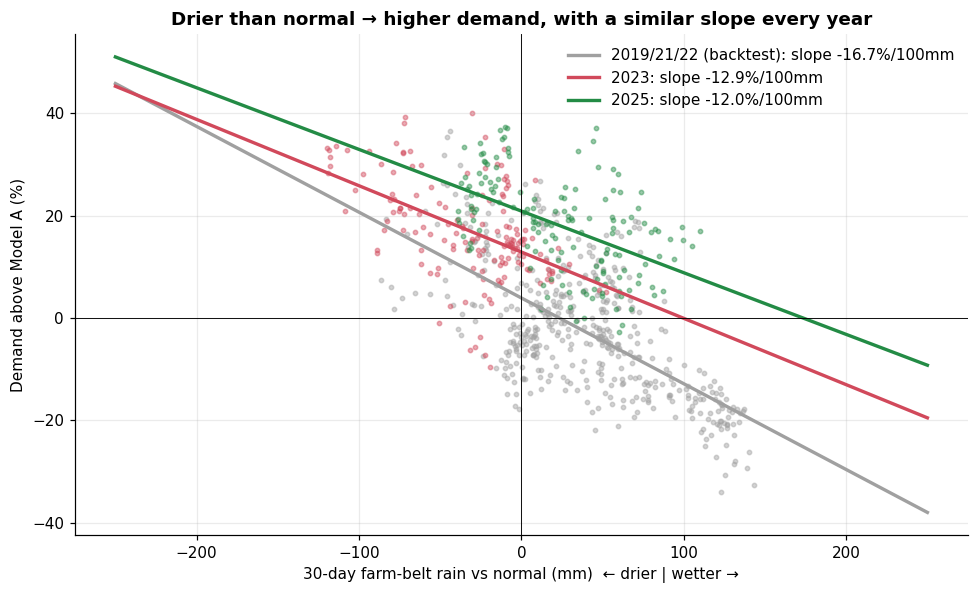

In [4]:
fig, ax = plt.subplots(figsize=(9, 5.5))
sets = {"2019/21/22 (backtest)": (bd[bd.index.month.isin([8, 9, 10, 11, 12])], plots.COLORS["muted"]),
        "2023": (d.loc["2023-08-01":"2023-12-31"], plots.COLORS["highlight"]),
        "2025": (d.loc["2025-08-01":"2025-12-31"], "#238b45")}
xs = np.linspace(-250, 250, 50)
for label, (fr, c) in sets.items():
    ax.scatter(fr.rain_30d_anom, fr["gap_A_%"], s=8, alpha=0.45, color=c)
    r = rain_regression(fr)
    ax.plot(xs, r["intercept %"] + r["slope % per 100mm"] * xs / 100, color=c, lw=2.2,
            label=f"{label}: slope {r['slope % per 100mm']:.1f}%/100mm")
ax.axvline(0, color="black", lw=0.6); ax.axhline(0, color="black", lw=0.6)
ax.set_xlabel("30-day farm-belt rain vs normal (mm)  ← drier | wetter →")
ax.set_ylabel("Demand above Model A (%)")
ax.set_title("Drier than normal → higher demand, with a similar slope every year")
ax.legend(); plt.tight_layout(); plots.save(fig, "06_rain_sensitivity"); plt.show()

In [5]:
# Drought effect for Aug–Oct 2023 in % and MW
aug_oct = d.loc["2023-08-01":"2023-10-31"]
slope = reg.loc["Aug–Dec 2023", "slope % per 100mm"]; slope_se = reg.loc["Aug–Dec 2023", "slope se"]
hist_slope = reg.loc["Backtest 2019/21/22 (no scheme)", "slope % per 100mm"]
mean_anom = aug_oct.rain_30d_anom.mean()
base_mw = aug_oct.pred_A.mean()
eff = slope * mean_anom / 100; eff_lo = (slope - 1.96 * slope_se) * mean_anom / 100; eff_hi = (slope + 1.96 * slope_se) * mean_anom / 100
eff_hist = hist_slope * mean_anom / 100
print(f"Aug–Oct 2023 mean 30-day rain anomaly: {mean_anom:.0f} mm")
print(f"Drought effect using 2023's own slope:     {eff:+.1f}%  (95% CI {min(eff_lo, eff_hi):+.1f} to {max(eff_lo, eff_hi):+.1f}%)  = {eff / 100 * base_mw:,.0f} MW")
print(f"Drought effect using pre-scheme slope:     {eff_hist:+.1f}%  = {eff_hist / 100 * base_mw:,.0f} MW")
print(f"Model B estimate (Notebook 05):            {(aug_oct.pred_B.mean() / aug_oct.pred_A.mean() - 1) * 100:+.1f}%  = {aug_oct.pred_B.mean() - aug_oct.pred_A.mean():,.0f} MW")
print(f"Total excess over Model A, Aug–Oct 2023:   {(aug_oct.load_mw.mean() / base_mw - 1) * 100:+.1f}%  = {aug_oct.load_mw.mean() - base_mw:,.0f} MW")

Aug–Oct 2023 mean 30-day rain anomaly: -46 mm
Drought effect using 2023's own slope:     +5.9%  (95% CI +3.6 to +8.3%)  = 514 MW
Drought effect using pre-scheme slope:     +7.7%  = 664 MW
Model B estimate (Notebook 05):            +5.2%  = 445 MW
Total excess over Model A, Aug–Oct 2023:   +21.5%  = 1,860 MW


### Step 4.3 — Fingerprints: in which hours does each part sit?
*Why:* run the same regression separately for each block of hours (Aug–Dec). The **drought part** and the
**persistent part** each get their own hour profile.

In [6]:
blocks = {"night 0–5h": range(0, 6), "morning 6–9h": range(6, 10), "day 10–16h": range(10, 17),
          "evening 18–22h": range(18, 23)}
fp = []
for yr in [2023, 2024, 2025]:
    for bname, hh in blocks.items():
        x = cf[cf.hour.isin(list(hh))].loc[f"{yr}-08-01":f"{yr}-12-31"].resample("D").mean().dropna()
        x["gap_A_%"] = (x.load_mw / x.pred_A - 1) * 100
        x = x.join(anom)
        r = rain_regression(x)
        fp.append({"year": yr, "hours": bname, "persistent part %": r["intercept %"],
                   "drought part %": r["slope % per 100mm"] * x.rain_30d_anom.mean() / 100})
fp = pd.DataFrame(fp)
fp_t = fp.pivot(index="hours", columns="year").round(1).reindex(list(blocks))
fp_t

persistent part %             drought part %          
year                        2023  2024  2025           2023 2024 2025
hours                                                                
night 0–5h                  15.6   9.9  21.6            3.9 -0.3 -3.6
morning 6–9h                11.3  12.7  22.7            3.2 -0.9 -2.3
day 10–16h                  16.2  11.9  22.9            6.8 -0.2 -3.6
evening 18–22h               6.9   7.8  16.1            1.4  0.6 -1.5

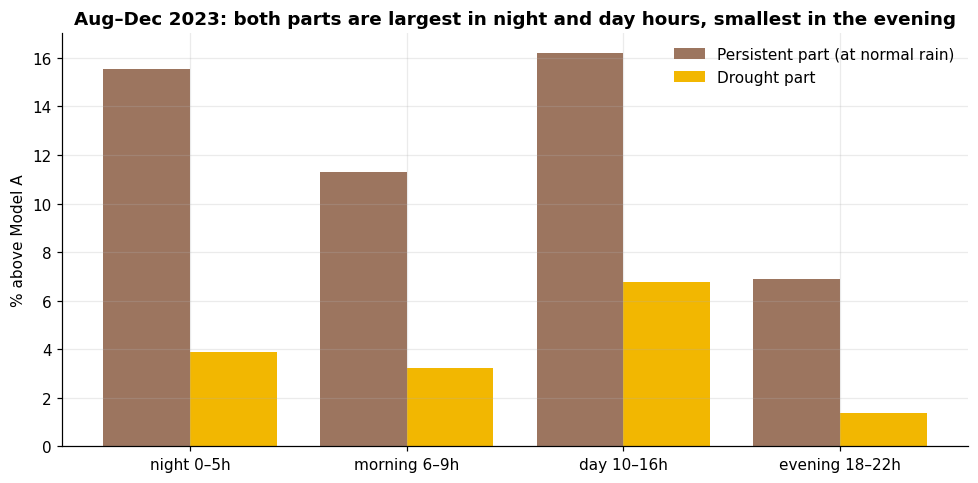

In [7]:
f23 = fp[fp.year == 2023].set_index("hours").reindex(list(blocks))
fig, ax = plt.subplots(figsize=(9, 4.5))
x = np.arange(len(f23))
ax.bar(x - 0.2, f23["persistent part %"], width=0.4, color=plots.COLORS["central_import"], label="Persistent part (at normal rain)")
ax.bar(x + 0.2, f23["drought part %"], width=0.4, color=plots.COLORS["solar"], label="Drought part")
ax.set_xticks(x, f23.index); ax.set_ylabel("% above Model A")
ax.set_title("Aug–Dec 2023: both parts are largest in night and day hours, smallest in the evening")
ax.legend(); plt.tight_layout(); plots.save(fig, "06_fingerprints"); plt.show()

### Step 4.4 — Weekday vs Sunday: households, farms or businesses?
*Why:* offices and many industries slow down on Sundays; households and farm pumps do not. If the persistent step
were mainly **commercial/industrial growth**, it would be **smaller on Sundays**. If it is **households or farms**,
it should be about the **same every day**.

In [8]:
cf["gap_B_mw"] = cf.load_mw - cf.pred_B
wk = []
for yr in [2023, 2024, 2025]:
    x = cf.loc[f"{yr}-08-01":f"{yr}-12-31"]
    wk.append({"year": yr, "Mon–Fri (MW)": x[x.dow < 5].gap_B_mw.mean(), "Saturday (MW)": x[x.dow == 5].gap_B_mw.mean(),
               "Sunday (MW)": x[x.dow == 6].gap_B_mw.mean()})
wk = pd.DataFrame(wk).set_index("year")
wk["Sunday vs weekday"] = (wk["Sunday (MW)"] / wk["Mon–Fri (MW)"] - 1) * 100
wk.round(0)

,Mon–Fri (MW),Saturday (MW),Sunday (MW),Sunday vs weekday
year,,,,
2023,1272.0,1224.0,1258.0,-1.0
2024,1259.0,1199.0,1116.0,-11.0
2025,1567.0,1508.0,1364.0,-13.0


### Step 4.5 — Outside evidence: is the step the right size to be Gruha Jyothi?
*Why:* Riley — "look for evidence inside **or outside** the data". Official figures give household consumption
growth in the scheme's first year; combined with the household share of total consumption, they tell us roughly how
many MW the scheme *could* have added at most.

| Input | Value | Source |
|---|---|---|
| Household (domestic) share of Karnataka consumption | ~22% (2016-17); use **20–25%** | Karnataka Economic Survey 2017-18, via ThePrint |
| Agriculture (pumpsets) share | ~40% (2016-17) | same |
| Household consumption growth, Aug 2023 – Jul 2024 | **+7% to +11%** (beneficiaries +7.13%; domestic +11.35% reported) | Deccan Herald, Varthabharati |

Upper bound: assume **all** of that household growth is caused by the scheme (it is not — normal growth is ~3%/yr).

In [9]:
step_mw = cf.loc["2023-08-01":"2023-10-31"].gap_B_mw.mean()
base = cf.loc["2023-08-01":"2023-10-31"].pred_A.mean()
rows = []
for share in (0.20, 0.25):
    for growth in (0.07, 0.11):
        hh = base * share * growth
        rows.append({"household share": f"{share:.0%}", "household growth": f"{growth:.0%}",
                     "implied MW (upper bound)": hh, "as % of persistent step": hh / step_mw * 100})
hh_tbl = pd.DataFrame(rows).round(0)
print(f"Persistent step, Aug–Oct 2023: {step_mw:,.0f} MW   (expected base load {base:,.0f} MW)")
hh_tbl

Persistent step, Aug–Oct 2023: 1,414 MW   (expected base load 8,640 MW)


,household share,household growth,implied MW (upper bound),as % of persistent step
0,20%,7%,121.0,9.0
1,20%,11%,190.0,13.0
2,25%,7%,151.0,11.0
3,25%,11%,238.0,17.0


### Step 4.6 — Putting it together: the split of the Aug–Oct 2023 excess

In [10]:
total = aug_oct.load_mw.mean() - base_mw
drought_est = {"2023's own rain slope": eff / 100 * base_mw,
               "pre-scheme rain slope": eff_hist / 100 * base_mw,
               "Model B (Notebook 05)": aug_oct.pred_B.mean() - aug_oct.pred_A.mean()}
hh_lo, hh_hi = hh_tbl["implied MW (upper bound)"].min(), hh_tbl["implied MW (upper bound)"].max()
d_lo, d_hi = min(drought_est.values()), max(drought_est.values())

split = pd.DataFrame({
    "low MW": [d_lo, 0, total - d_hi - hh_hi],
    "high MW": [d_hi, hh_hi, total - d_lo],
}, index=["Drought (temporary)", "Gruha Jyothi (households, upper bound)", "Other persistent demand"])
split["low % of excess"] = split["low MW"] / total * 100
split["high % of excess"] = split["high MW"] / total * 100
print(f"Total excess over Model A, Aug–Oct 2023: {total:,.0f} MW")
print("Drought estimates (MW):", {k: round(v) for k, v in drought_est.items()})
split.round(0)

Total excess over Model A, Aug–Oct 2023: 1,860 MW
Drought estimates (MW): {"2023's own rain slope": 514, 'pre-scheme rain slope': 664, 'Model B (Notebook 05)': 445}


,low MW,high MW,low % of excess,high % of excess
Drought (temporary),445.0,664.0,24.0,36.0
"Gruha Jyothi (households, upper bound)",0.0,238.0,0.0,13.0
Other persistent demand,958.0,1414.0,51.0,76.0


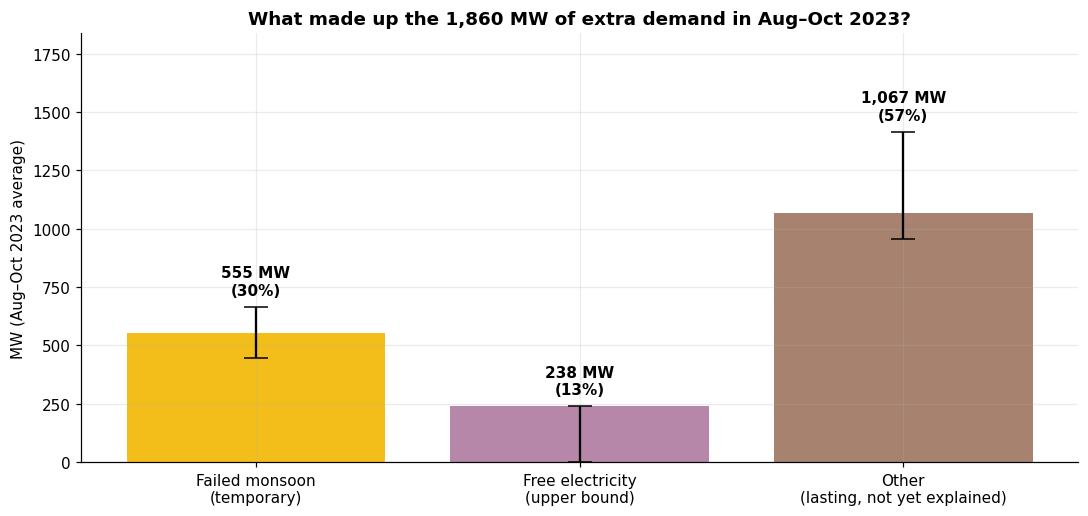

In [11]:
mid = pd.Series({"Failed monsoon\n(temporary)": np.mean([d_lo, d_hi]),
                 "Free electricity\n(upper bound)": hh_hi,
                 "Other\n(lasting, not yet explained)": total - np.mean([d_lo, d_hi]) - hh_hi})
lo = pd.Series([d_lo, 0, total - d_hi - hh_hi], index=mid.index)
hi = pd.Series([d_hi, hh_hi, total - d_lo], index=mid.index)
fig, ax = plt.subplots(figsize=(10, 4.8))
colors = [plots.COLORS["solar"], "#b07aa1", plots.COLORS["central_import"]]
ax.bar(mid.index, mid.values, color=colors, yerr=[mid - lo, hi - mid], capsize=8, alpha=0.9)
for i, v in enumerate(mid.values):
    ax.text(i, hi.iloc[i] + 40, f"{v:,.0f} MW\n({v / total:.0%})", ha="center", va="bottom", fontsize=10, fontweight="bold")
ax.set_ylabel("MW (Aug–Oct 2023 average)")
ax.set_title(f"What made up the {total:,.0f} MW of extra demand in Aug–Oct 2023?")
ax.set_ylim(0, max(hi) * 1.3)
plt.tight_layout(); plots.save(fig, "06_final_split"); plt.show()

## 5. Result
**1. Timing — the step did not switch on at 1 Aug**
- Best change point: **14 Aug 2023** (before +4.7%, after +16.9% above Model B). Forcing it at 1 Aug fits 52% worse.
- The excess **built up gradually during the long dry spell of 1–20 Aug** (almost no rain) and fell back when rain came in early September. A policy switch-on would look like a sharp jump at 1 Aug, which is not what happened.

**2. The failed monsoon, measured inside 2023** *(scheme constant after 1 Aug, so day-to-day rain links are monsoon effects)*
| Period | Demand rise per 100 mm rain shortfall | R² |
|---|---|---|
| 2019/21/22 (before scheme, unseen by model) | **+16.7%** (± 2.4) | 0.42 |
| Aug–Dec 2023 | **+12.9%** (± 2.6) | 0.25 |
| Aug–Dec 2025 | **+12.0%** (± 3.8) | 0.24 |
| Aug–Dec 2024 | ~0 (no clear link) | 0.00 |

The rain–demand link is **real and long-standing**: it existed before the scheme with a similar strength. For Aug–Oct 2023 (rain 46 mm below normal over 30 days on average), it gives:
- **514 MW** (+5.9%, 95% CI +3.6% to +8.3%) using 2023's own slope
- **664 MW** using the pre-scheme slope
- **445 MW** from Model B (Notebook 05)

**3. Hour fingerprints (Aug–Dec 2023, % above Model A)**
| Hours | Lasting part | Monsoon part |
|---|---|---|
| Night 0–5h | 15.6 | 3.9 |
| Morning 6–9h | 11.3 | 3.2 |
| Day 10–16h | 16.2 | **6.8** |
| Evening 18–22h | **6.9** | 1.4 |

The monsoon part is largest in daytime farm-pump hours, as expected. The lasting part is also smallest in the evening, the main household hours.

**4. Weekday vs Sunday (excess over Model B, MW)**
| | Mon–Fri | Sat | Sun | Sun vs weekday |
|---|---|---|---|---|
| 2023 | 1,272 | 1,224 | 1,258 | **−1%** |
| 2024 | 1,259 | 1,199 | 1,116 | −11% |
| 2025 | 1,567 | 1,508 | 1,364 | −13% |

In 2023 the lasting excess was **the same every day of the week**, so it is not office/industry demand (which drops on Sundays). In 2024–25 part of it does look like business growth.

**5. Outside evidence on free electricity**
Household share of consumption ~20–25% × household growth +7–11% (official, first year of scheme) → **121–238 MW at most**, which is only **9–17% of the lasting step**. Free electricity cannot be the main source of the lasting increase.

**6. Final split of the Aug–Oct 2023 excess (1,860 MW)**
| Cause | MW | Share |
|---|---|---|
| **Failed monsoon** (temporary) | 445–664 | **24–36%** |
| **Free electricity** (upper bound) | 0–238 | **0–13%** |
| **Other lasting increase** | 958–1,414 | **51–76%** |

**Expectations vs results:** monsoon effect visible inside 2023 ✓. Free-electricity expectations ✗: no sharp 1 Aug switch-on, not concentrated in household hours, and the size implied by official data is small.

Figures: `06_step_timing`, `06_rain_sensitivity`, `06_fingerprints`, `06_final_split`.

## 6. Caveats
- **The "other" part is not explained here.** Candidates: (a) normal demand growth sped up after 2022 (Model A assumes 2.96%/yr), (b) lasting farm-side changes after the drought (new pump connections, longer supply hours), (c) a household response bigger than official figures show. Notebook 07 tests (a) directly.
- **The free-electricity bound relies on news figures** (household growth 7–11%) and an old category share (22% in 2016-17). If the household share is now higher, the bound rises somewhat, but it would need to be ~5× larger to explain the lasting step.
- **The monsoon share may be underestimated:** the gradual build-up during the long August dry spell suggests the models capture prolonged dryness only partly. Some of the 2023 "other" may still be monsoon.
- 2024 shows no clear rain–demand link, unlike other years. Not investigated.
- Regressions use a single rain variable (30-day anomaly); 7-day and 60-day versions give similar or weaker fits.
- "Day/night = farms, evening = households" is an approximation, not a measurement.

## 7. Next
**Notebook 07 — Robustness checks** (try to break the findings):
- **Faster growth trend** (4%, 5%, 6%/yr): how much of the "other" part disappears?
- **Placebo dates:** pretend the scheme started 1 Aug 2021 or 2022 — does the method find a fake effect?
- **Exclude the 8 flagged days** (Oct–Nov 2023 cross-check disagreements).
- **2016:** an equally dry year with no scheme — did demand rise in the same way?